# Person 2: Exploratory Data Analysis
**Models this supports:** SVM (RBF) and Gaussian Naive Bayes

**Questions this notebook answers:**
- Is the data clean, and is the official split safe from leakage?
- Does the data meet what each model assumes?
- Could the data source be affecting results?

Feature analysis uses the **training split only**, so the test set stays locked.

**How to run:** use *Run > Run All Cells*. This notebook only reads the data and saves `eda_*.png` files to `plots/`. It doesn't change any models.

## 1. Setup and load

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

PLOTS = Path("plots")
PLOTS.mkdir(exist_ok=True)
CLASS_COLORS = {"vessel_like": "#2a78d6", "ambient": "#eb6834", "unknown": "#1baf7a"}
CLASSES = list(CLASS_COLORS)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

df = pd.read_csv("../data/features/features.csv")
meta = pd.read_csv("../data/metadata/master_metadata.csv")
with open("../data/features/selected_features.json") as f:
    sel = json.load(f)
feature_cols = sel["selected_features"]

df = df.merge(meta[["clip_id", "source_dataset"]].rename(columns={"clip_id": "source_clip_id"}),
              on="source_clip_id", how="left")
train = df[df["split"] == "train"]   # feature analysis uses training data only
X = train[feature_cols]
print(f"All data: {df.shape} | Train: {train.shape} | Features: {len(feature_cols)}")

All data: (3579, 222) | Train: (2756, 222) | Features: 66


## 2. Data checks
These stop with an error if the data isn't what we expect.

In [2]:
print(pd.crosstab(df["label"], df["split"], margins=True), "\n")
missing = [c for c in feature_cols if c not in df.columns]
clips_in_many_splits = (df.groupby("source_clip_id")["split"].nunique() > 1).sum()
assert len(df) == 3579 and len(feature_cols) == 66 and not missing
assert clips_in_many_splits == 0
assert df["source_dataset"].notna().all()
print("Missing features:", missing)
print("Clips in more than one split:", clips_in_many_splits)
print("Largest segments-per-clip:", df.groupby("source_clip_id").size().max())

split        test  train  val   All
label                              
ambient        20    153   19   192
unknown         9     66    8    83
vessel_like   453   2537  314  3304
All           482   2756  341  3579 

Missing features: []
Clips in more than one split: 0
Largest segments-per-clip: 101


## 3. Classes by data source
Shows whether a class comes mostly from one data source.

label           vessel_like  ambient  unknown
source_dataset                               
DeepShip               2779        0        0
ShipsEar                368       32        0
Synthetic               157      160       83 

Share of each class by source:
label           vessel_like  ambient  unknown
source_dataset                               
DeepShip              0.841    0.000      0.0
ShipsEar              0.111    0.167      0.0
Synthetic             0.048    0.833      1.0


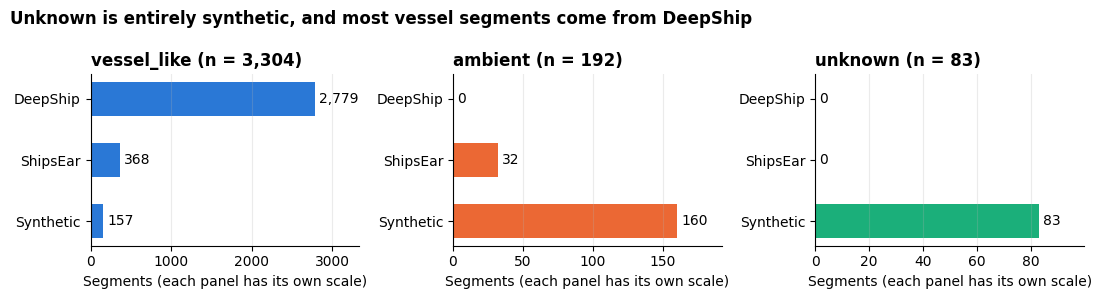

In [3]:
by_source = pd.crosstab(df["source_dataset"], df["label"])[CLASSES]
print(by_source, "\n")
print("Share of each class by source:")
print((by_source / by_source.sum()).round(3))

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, cls in zip(axes, CLASSES):
    counts = by_source[cls]
    bars = ax.barh(counts.index, counts.values, color=CLASS_COLORS[cls], height=0.55)
    ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=3)
    ax.set_title(f"{cls} (n = {counts.sum():,})", loc="left", fontweight="bold")
    ax.set_xlabel("Segments (each panel has its own scale)")
    ax.set_xlim(0, counts.max() * 1.2)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
fig.suptitle("Unknown is entirely synthetic, and most vessel segments come from DeepShip",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(PLOTS / "eda_class_by_source.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Skew, outliers and feature scale
Scale matters for SVM. Skew matters for the Gaussian assumption in Naive Bayes.

Features with |skew| > 1: 25 of 66
Features with |skew| > 2: 6 of 66
Largest / smallest feature std: 137,909,210x

                              skew  abs_skew  kurtosis  pct_over_3sd    std
spectral_flatness_min        11.96     11.96    228.52          2.00   0.00
spectral_flatness_median      3.10      3.10      7.66          7.73   0.27
mfcc_1_std                    2.37      2.37      5.89          4.54  35.13
mfcc_2_std                    2.19      2.19      5.54          4.79  18.01
peak_amp_3                   -2.12      2.12      7.32          1.85  19.64
spectral_flatness_mean        2.11      2.11      3.68          2.58   0.20
peak_amp_2                   -1.93      1.93      6.27          1.74  17.50
peak_amp_1                   -1.61      1.61      3.89          1.85  15.73
spectral_contrast_band6_max  -1.59      1.59      1.88          1.67  16.03
spectral_contrast_band5_max  -1.38      1.38      1.23          1.12  15.56


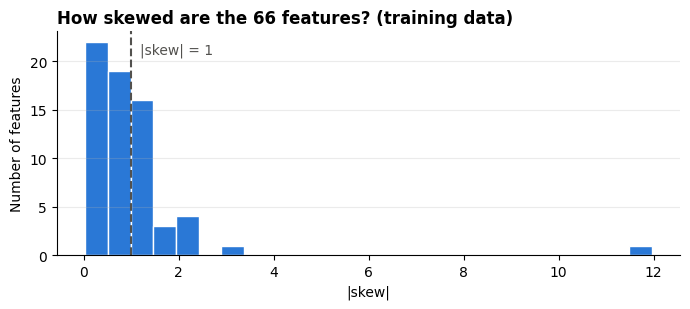

In [4]:
skew = X.skew()
z = (X - X.mean()) / X.std()
summary = pd.DataFrame({"skew": skew, "abs_skew": skew.abs(),
                        "kurtosis": X.kurtosis(),
                        "pct_over_3sd": (z.abs() > 3).mean() * 100,
                        "std": X.std()})
print(f"Features with |skew| > 1: {(summary['abs_skew'] > 1).sum()} of {len(summary)}")
print(f"Features with |skew| > 2: {(summary['abs_skew'] > 2).sum()} of {len(summary)}")
print(f"Largest / smallest feature std: {X.std().max() / X.std().min():,.0f}x\n")
print(summary.sort_values("abs_skew", ascending=False).head(10).round(2))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(summary["abs_skew"], bins=25, color="#2a78d6", edgecolor="white")
ax.axvline(1, color="#52514e", linestyle="--", linewidth=1.5)
ax.annotate("|skew| = 1", xy=(1, ax.get_ylim()[1] * 0.9), xytext=(6, 0),
            textcoords="offset points", color="#52514e")
ax.set_title("How skewed are the 66 features? (training data)", loc="left", fontweight="bold")
ax.set_xlabel("|skew|")
ax.set_ylabel("Number of features")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(PLOTS / "eda_feature_skew.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Feature correlation
Naive Bayes assumes features are independent within each class. High correlation works against that.

Feature pairs: 2145
  |r| > 0.9: 6 (0.3%)
  |r| > 0.7: 75 (3.5%)
  |r| > 0.5: 222 (10.3%)

Most correlated pairs:
spectral_centroid_median  zcr_median                  0.939
spectral_rolloff_median   spectral_centroid_median    0.921
peak_amp_3                peak_amp_2                  0.915
mfcc_11_std               mfcc_12_std                 0.905
mfcc_1_std                mfcc_2_std                  0.903
spectral_rolloff_median   spectral_rolloff_mean       0.902
mfcc_10_std               mfcc_11_std                 0.900
spectral_rolloff_mean     spectral_centroid_mean      0.899
dtype: float64


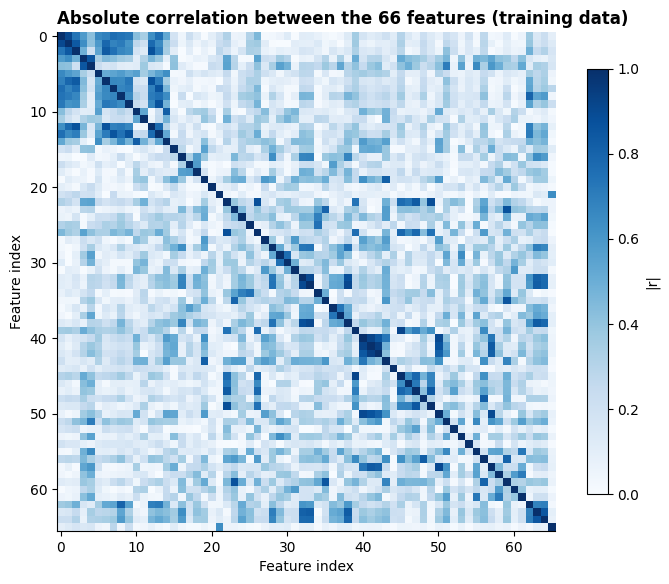

In [5]:
corr = X.corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
print(f"Feature pairs: {len(pairs)}")
for t in (0.9, 0.7, 0.5):
    print(f"  |r| > {t}: {(pairs > t).sum()} ({(pairs > t).mean():.1%})")
print("\nMost correlated pairs:")
print(pairs.head(8).round(3))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_title("Absolute correlation between the 66 features (training data)", loc="left", fontweight="bold")
ax.set_xlabel("Feature index")
ax.set_ylabel("Feature index")
ax.grid(False)
fig.colorbar(im, ax=ax, label="|r|", shrink=0.8)
fig.tight_layout()
fig.savefig(PLOTS / "eda_feature_correlation.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Are the top features Gaussian within each class?
Naive Bayes assumes a normal distribution **within each class**, so these plots are split by class.

Top 5 features by ANOVA: ['mfcc_1_std', 'mfcc_2_std', 'delta_mfcc_2_min', 'mfcc_2_max', 'mfcc_2_mean']


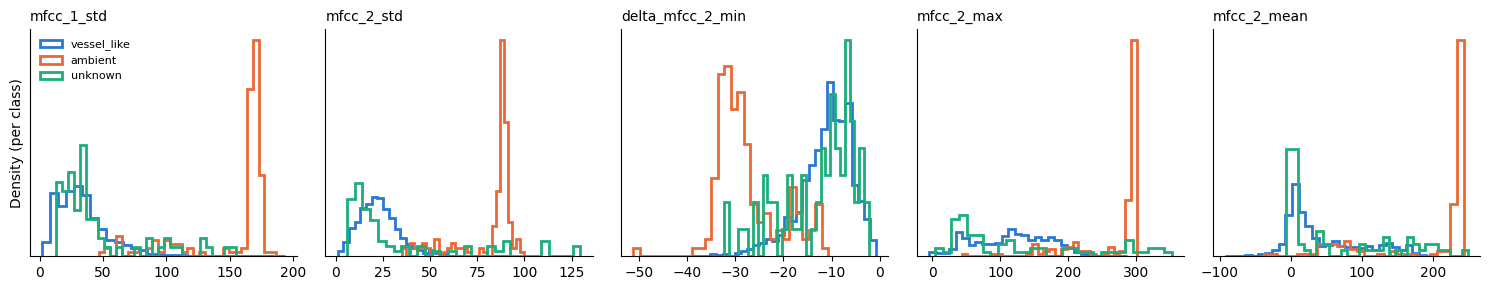

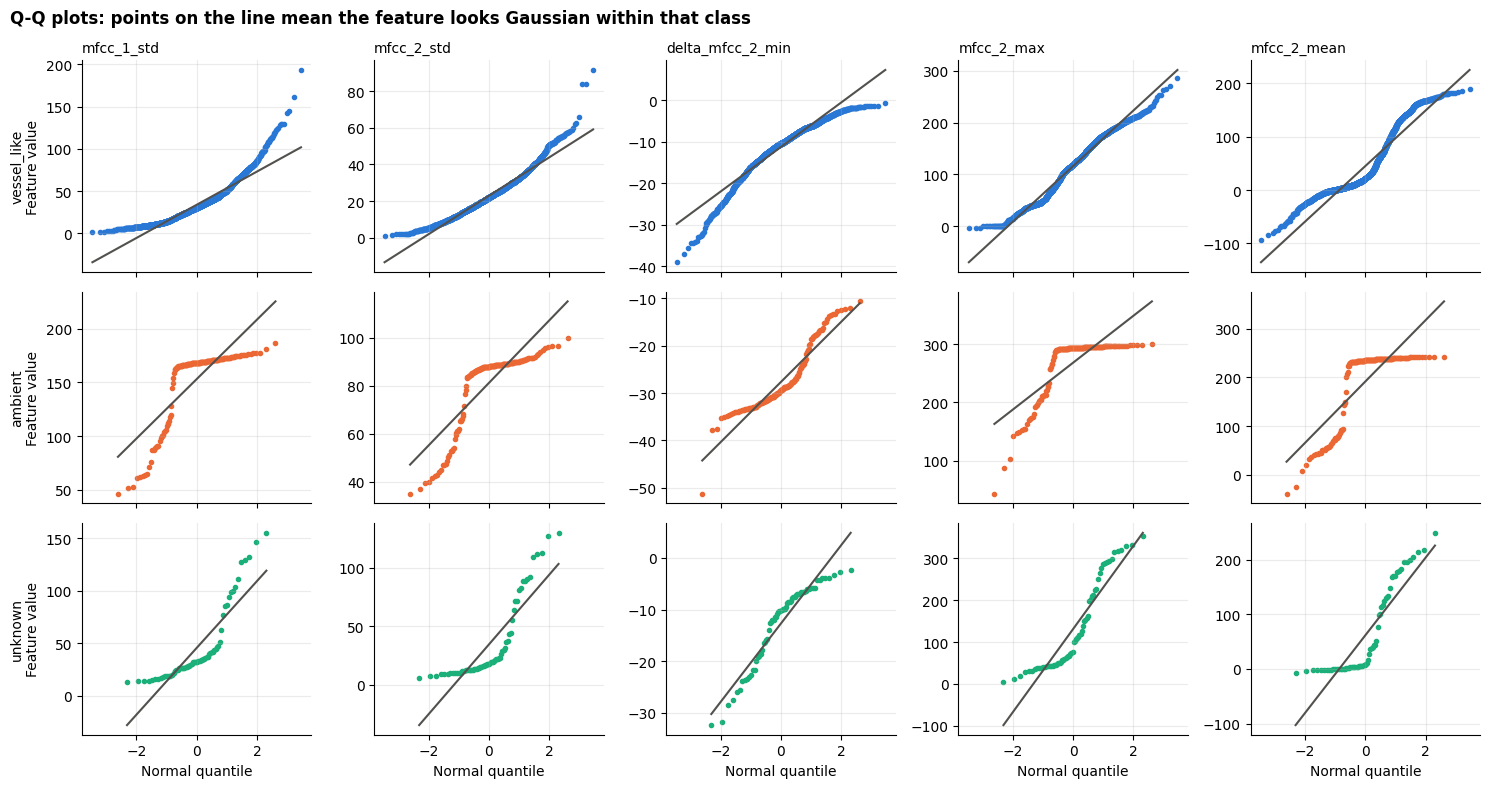

Q-Q fit (closer to 1 = more Gaussian):
class             ambient  unknown  vessel_like
feature                                        
delta_mfcc_2_min    0.947    0.956        0.971
mfcc_1_std          0.803    0.872        0.947
mfcc_2_max          0.787    0.931        0.990
mfcc_2_mean         0.805    0.886        0.942
mfcc_2_std          0.836    0.861        0.980


In [6]:
top5 = [c for c in sel["top_anova"] if c in feature_cols][:5]
print("Top 5 features by ANOVA:", top5)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, feat in zip(axes, top5):
    for cls in CLASSES:
        ax.hist(train.loc[train["label"] == cls, feat], bins=30, density=True,
                histtype="step", linewidth=2, color=CLASS_COLORS[cls], label=cls)
    ax.set_title(feat, fontsize=10, loc="left")
    ax.set_yticks([])
    ax.grid(False)
axes[0].set_ylabel("Density (per class)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(PLOTS / "eda_top5_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(3, 5, figsize=(15, 8), sharex=True)
rows = []
for r, cls in enumerate(CLASSES):
    subset = train[train["label"] == cls]
    for c, feat in enumerate(top5):
        ax = axes[r, c]
        (osm, osr), (slope, intercept, fit_r) = stats.probplot(subset[feat], dist="norm")
        ax.scatter(osm, osr, s=9, color=CLASS_COLORS[cls])
        ax.plot(osm, slope * osm + intercept, color="#52514e", linewidth=1.5)
        rows.append({"class": cls, "feature": feat, "qq_r": fit_r})
        if r == 0:
            ax.set_title(feat, fontsize=10, loc="left")
        if c == 0:
            ax.set_ylabel(f"{cls}\nFeature value")
        if r == 2:
            ax.set_xlabel("Normal quantile")
fig.suptitle("Q-Q plots: points on the line mean the feature looks Gaussian within that class",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(PLOTS / "eda_top5_qq.png", dpi=200, bbox_inches="tight")
plt.show()
print("Q-Q fit (closer to 1 = more Gaussian):")
print(pd.DataFrame(rows).pivot(index="feature", columns="class", values="qq_r").round(3))

## 7. Recording quality
Checks whether poor-quality segments are spread evenly across the splits.

In [7]:
poor = pd.crosstab(df["label"], df["is_poor_quality"], margins=True)
print(poor, "\n")
print("is_poor_quality used as a model feature:", "is_poor_quality" in feature_cols)
print("Poor-quality share by split:")
print(df.groupby("split")["is_poor_quality"].mean().round(3))
print("\nClip-level counts (independent recordings) in train:")
print(train.groupby("label")["source_clip_id"].nunique())

is_poor_quality   0.0  1.0   All
label                           
ambient           192    0   192
unknown            70   13    83
vessel_like      2959  345  3304
All              3221  358  3579 

is_poor_quality used as a model feature: False
Poor-quality share by split:
split
test     0.100
train    0.107
val      0.041
Name: is_poor_quality, dtype: float64

Clip-level counts (independent recordings) in train:
label
ambient        153
unknown         66
vessel_like    469
Name: source_clip_id, dtype: int64


## 8. Does the data source change the features?
Compares the same class across different sources.

               mfcc_1_std              mfcc_2_std            
                    count   mean   std      count  mean   std
source_dataset                                               
ShipsEar               25   94.0  37.2         25  51.1  11.4
Synthetic             128  164.5  17.5        128  87.0   6.8 

vessel_like segments by source (same features):
               mfcc_1_std             mfcc_2_std            
                    count  mean   std      count  mean   std
source_dataset                                              
DeepShip             2118  31.7  19.5       2118  21.4   9.8
ShipsEar              294  49.5  25.8        294  30.6  12.0
Synthetic             125  32.5   8.0        125  29.5  11.0


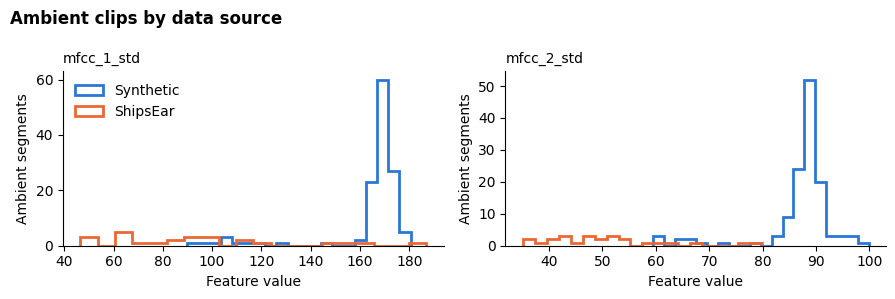

In [8]:
amb = train[train["label"] == "ambient"]
print(amb.groupby("source_dataset")[top5[:2]].agg(["count", "mean", "std"]).round(1), "\n")
print("vessel_like segments by source (same features):")
print(train[train["label"] == "vessel_like"].groupby("source_dataset")[top5[:2]].agg(["count", "mean", "std"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, feat in zip(axes, top5[:2]):
    for src, color in [("Synthetic", "#2a78d6"), ("ShipsEar", "#eb6834")]:
        ax.hist(amb.loc[amb["source_dataset"] == src, feat], bins=20, histtype="step",
                linewidth=2, color=color, label=src)
    ax.set_title(feat, loc="left", fontsize=10)
    ax.set_xlabel("Feature value")
    ax.set_ylabel("Ambient segments")
    ax.grid(False)
axes[0].legend(frameon=False)
fig.suptitle("Ambient clips by data source", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(PLOTS / "eda_ambient_by_source.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Conclusions

| Finding | What it means for the models |
|---|---|
| Feature scales differ by about 138 million times | SVM must have scaling, or the largest features would dominate |
| 25 of 66 features have \|skew\| > 1, and the Q-Q plots curve away from the line | The Gaussian assumption is weak, so `PowerTransformer` is worth testing for Naive Bayes |
| 6 pairs have \|r\| > 0.9 and 75 have \|r\| > 0.7 | Independence is partly violated, which can make Naive Bayes overconfident |
| Ambient's top features form two groups that split by source | Synthetic ambient is a tight spike and real ShipsEar ambient is spread out, so high ambient scores may not carry over to real recordings |
| All `unknown` clips are synthetic, and 84% of `vessel_like` segments are from DeepShip | A model may partly learn the data source rather than the sound, so results need checking by source |
| Validation has fewer poor-quality segments (4.1%, against about 10% in train and test) | Validation may be easier than test, so its scores may differ somewhat |

> If any number above differs from your output, trust the output and update this table.